In [414]:
import optiland
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland import analysis
from optiland import wavefront
from optiland.psf import FFTPSF
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from scipy.special import jv
from scipy.special import j1
import dynesty.pool as dypool
import dynesty
from dynesty import plotting as dyplot
import scipy

In [412]:
import multiprocess, dill
dill.settings['recurse'] = True
dypool.mp = multiprocess

In [36]:
be.set_backend("numpy")

In [387]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

def decompose_psf(psf, nterms=15, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=np.nan, **kwargs)
    basis_stack = np.stack(basis_set)  # shape: (nterms, npix, npix)
    psf_flat = psf.ravel()
    basis_flat = basis_stack.reshape(nterms, -1)
    numerators = np.dot(basis_flat, psf_flat)
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs

In [406]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):

    K=1000 #mm to micron
    T = 3600
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=12920)
    aperture1 = physical_apertures.RadialAperture(r_min=1380, r_max=6420) 
    a1 = physical_apertures.PolygonAperture(x=[1380, 6420, 6420, 1380], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[5410, 5710, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[-5410, -5710, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set fields
    pearl.set_field_type(field_type="angle")
    pearl.add_field(y=0.)

    # set wavelengths
    pearl.add_wavelength(value=WL, is_primary=True)

    # add surfaces
    pearl.add_surface(index=0, radius=be.inf, thickness=be.inf)

    pearl.add_surface(
        index=1,
        radius=-16256,
        thickness=-7400+pdz/K,
        dx=pdx/K,
        dy=pdy/K,
        rx=ptx/T,
        ry=pty/T,
        conic=-0.9953569,
        material="mirror",
        aperture=a,
        is_stop=True
    )
    pearl.add_surface(
        index=2,
        radius=-1660.575,
        thickness=+7500.732+sdz/K,
        dx=sdx/K,
        dy=sdy/K,
        rx=stx/T,
        ry=sty/T,
        conic=-1.566503,
        material="mirror",
        #aperture=aperture2
    )
    pearl.add_surface(
        index=3,
        radius=-1830.517,
        thickness=-933.63,
        conic=-0.718069,
        material="mirror",

    )

    pearl.add_surface(
        index=4,
        radius=be.inf,
        thickness=1221.21,
        material="mirror",

    )

    pearl.add_surface(index=5)

    return pearl

In [393]:
telescope = telescopeCreation(0.65, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)
psf = FFTPSF(telescope, field=(0, 0.17), wavelength=0.65, grid_size=256)
psf.strehl_ratio()

np.float64(0.38810672747743674)

In [423]:
from optiland.fileio import zemax_handler

In [425]:
bro = zemax_handler.load_zemax_file('Lazuli_Mark-11_DKim1_Release_HChoi02.zmx')

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

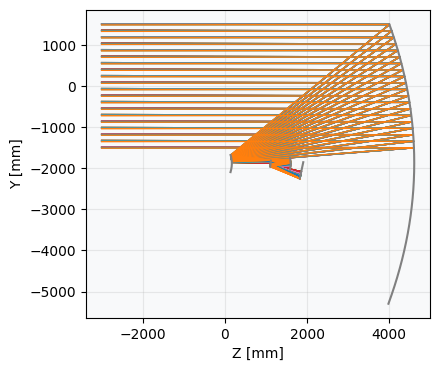

In [426]:
bro.draw(num_rays=20)

In [395]:
def find_bounds(psf, threshold=0.25):
        """Finds the bounding box coordinates for the non-zero elements in the
        PSF matrix.

        Args:
            psf (numpy.ndarray): The PSF matrix.
            threshold (float): The threshold value for determining non-zero
                elements in the PSF matrix. Default is 0.25.

        Returns:
            tuple: A tuple containing the minimum and maximum x and y
                coordinates of the bounding box.

        """
        thresholded_psf = psf > threshold
        non_zero_indices = np.argwhere(thresholded_psf)

        try:
            min_x, min_y = np.min(non_zero_indices, axis=0)
            max_x, max_y = np.max(non_zero_indices, axis=0)
        except ValueError:
            min_x, min_y = 0, 0
            max_x, max_y = psf.shape

        size = max(max_x - min_x, max_y - min_y)

        peak_x, peak_y = psf.shape[0] // 2, psf.shape[1] // 2

        min_x = peak_x - size / 2
        max_x = peak_x + size / 2
        min_y = peak_y - size / 2
        max_y = peak_y + size / 2

        min_x = max(0, min_x)
        min_y = max(0, min_y)
        max_x = min(psf.shape[0], max_x)
        max_y = min(psf.shape[1], max_y)

        return int(min_x), int(min_y), int(max_x), int(max_y)

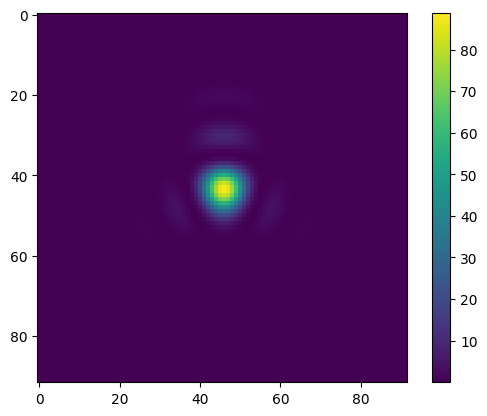

In [428]:
telescope = telescopeCreation(0.65, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)
psf = FFTPSF(bro, field=(0, 0.17), wavelength=0.65, grid_size=1024)
#psf.strehl_ratio()
#plt.imshow(psf.psf, norm=mcolors.LogNorm(vmin=1e-5, vmax=1))
min_x, min_y, max_x, max_y = find_bounds(psf.psf, 0.05)
psf_zoomed = psf.psf[min_x:max_x, min_y:max_y]
plt.imshow(psf_zoomed)
#plt.axhline(128, color='white', linestyle='--')
#plt.axvline(128, color='white', linestyle='--')
plt.colorbar()

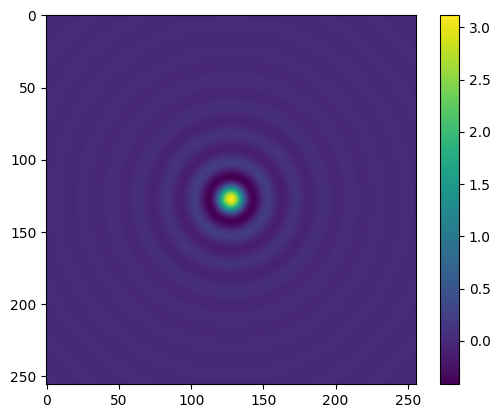

In [403]:
plt.imshow(basis_vectors(nterms=1)[0])
plt.colorbar()

In [ ]:
def genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = FFTPSF(telescope, field=(0, 0.17), wavelength=WL)
    PSF = psf.psf
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

In [408]:
#Truth

pdx_true = 5
pdy_true = -7

## PSF 
ct = genpsf(WL=650e-9, pdx=pdx_true, pdy=pdy_true, dterms=3)


In [417]:
C = np.array([[ 1.95085584e-05, -4.41845051e-07, -1.64161859e-06],
              [-4.41845051e-07,  7.91040997e-05, -2.02834252e-06],
              [-1.64161859e-06, -2.02834252e-06,  8.11550625e-05]])
Cinv = np.linalg.inv(C)  # precision matrix
lnorm = -0.5 * (np.log(2 * np.pi) * 3 + np.log(np.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    pdx,pdy = theta
    ## PSF
    c = genpsf(WL=650e-9, pdx=pdx, pdy=pdy, dterms=3)
    inv_sigma2 = 1.0 / (c**2)
    
    return -0.5 * np.dot(ct-c, np.dot(Cinv, ct-c)) + lnorm

# prior transform
def ptform(utheta):

    upx,upy = utheta

    mpx, spx = 0, 16  # mean and standard deviation
    lpx, hpx = -50, 50  # lower and upper bounds
    xpx = scipy.stats.truncnorm.ppf(upx, lpx, hpx, loc=mpx, scale=spx)

    mpy, spy = 0, 25  # mean and standard deviation
    lpy, hpy = -80, 80  # lower and upper bounds
    xpy = scipy.stats.truncnorm.ppf(upy, lpy, hpy, loc=mpy, scale=spy)

    return xpx,xpy

In [422]:
with dypool.Pool(8, loglike, ptform) as pool:

    dsampler = dynesty.DynamicNestedSampler(pool.loglike, pool.prior_transform, ndim=2, 
                                  sample='unif',pool=pool)
    dsampler.run_nested(maxiter=3000)
dres = dsampler.results

1814it [08:44,  1.22s/it, batch: 0 | bound: 3 | nc: 80 | ncall: 19243 | eff(%):  9.188 | loglstar:   -inf < 11.481 <    inf | logz:  9.319 +/-  0.044 | dlogz:  0.356 >  0.010] Process SpawnPoolWorker-30:
Process SpawnPoolWorker-32:
Process SpawnPoolWorker-29:
Process SpawnPoolWorker-28:
Process SpawnPoolWorker-27:
Process SpawnPoolWorker-25:
Process SpawnPoolWorker-26:
1821it [08:55,  3.40it/s, batch: 0 | bound: 4 | nc: 146 | ncall: 19583 | eff(%):  9.067 | loglstar:   -inf < 11.489 <    inf | logz:  9.322 +/-  0.044 | dlogz:  0.351 >  0.010]
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages

Exception while calling loglikelihood function:
  params: [11.06636775 -0.56018569]
  args: []
  kwargs: {}
  exception:


KeyboardInterrupt: 

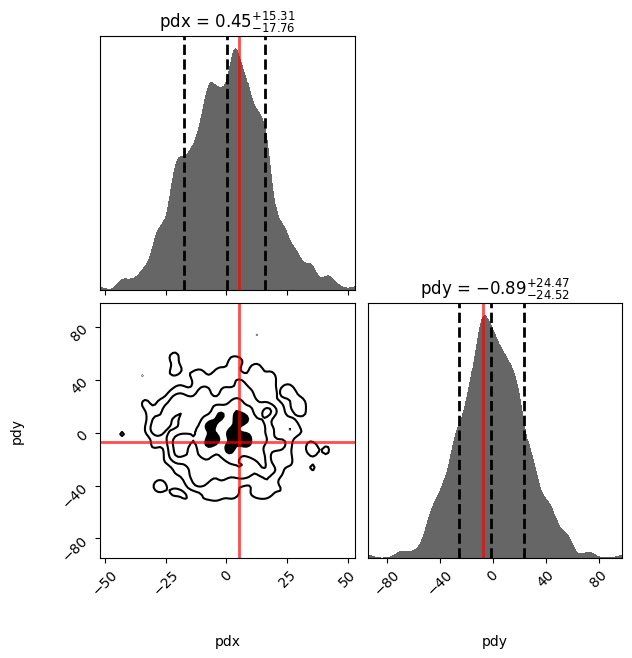

In [ ]:
plt.rcParams['text.usetex'] = False

labels = [r'pdx',r'pdy']
truths = [pdx_true,pdy_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1.] , quantiles=(0.16, 0.5, 0.84), title_quantiles=(0.16, 0.5, 0.84),
                              fig=plt.subplots(2, 2, figsize=(7, 7)))

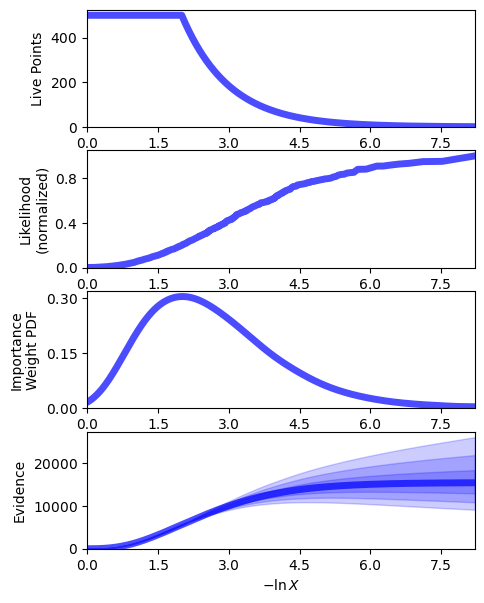

In [ ]:
fig, axes = dyplot.runplot(dres, fig=plt.subplots(4, 1, figsize=(5, 7)))

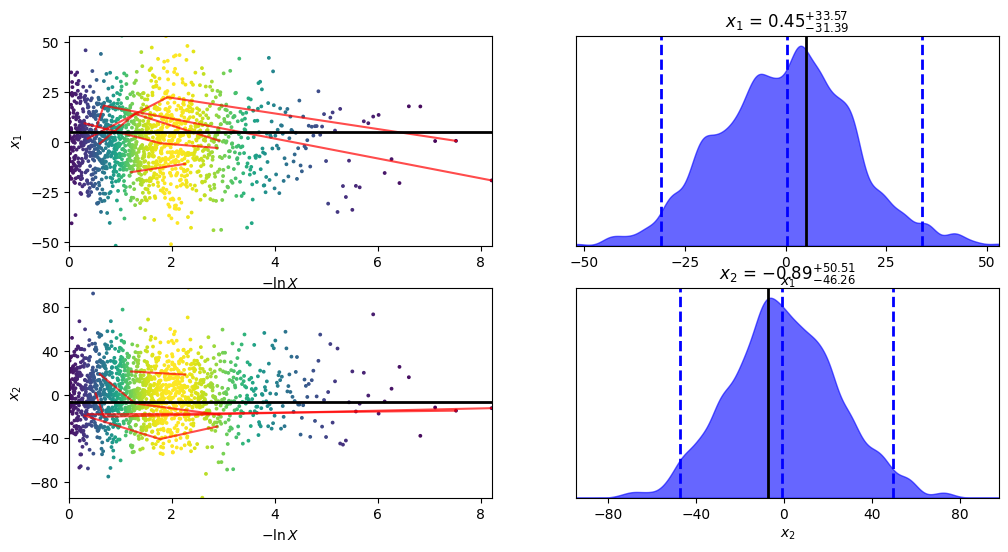

In [ ]:
fig, axes = dyplot.traceplot(dres, truths=truths,
                             truth_color='black', show_titles=True,
                             trace_cmap='viridis', connect=True,
                             connect_highlight=range(5))